In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import  files

In [9]:
arq = files.upload()

Saving naruto.jpg to naruto.jpg


array([[107, 107, 107, ..., 105, 109, 108],
       [107, 107, 107, ..., 100, 104, 106],
       [107, 107, 107, ...,  85, 101, 110],
       ...,
       [ 83,  83,  83, ..., 129, 129, 130],
       [ 83,  83,  83, ..., 130, 130, 130],
       [ 83,  83,  83, ..., 130, 130, 130]], dtype=uint8)
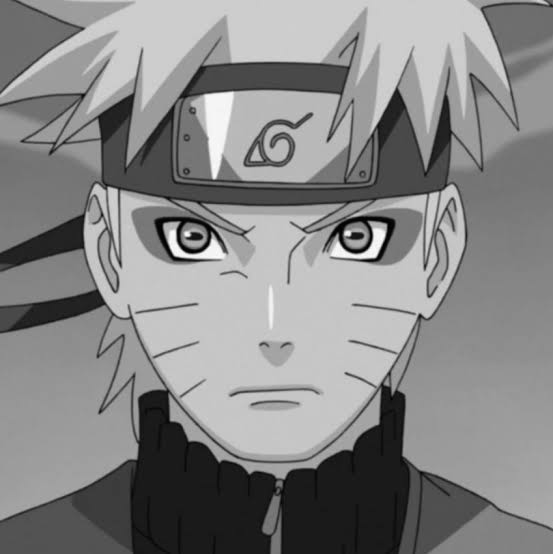

In [10]:
img_bgr = cv2.imread('naruto.jpg')
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_gray

In [15]:
alt = img_gray.shape[0]
lar = img_gray.shape[1]
alt, lar

(554, 553)

# Translação de exclusão

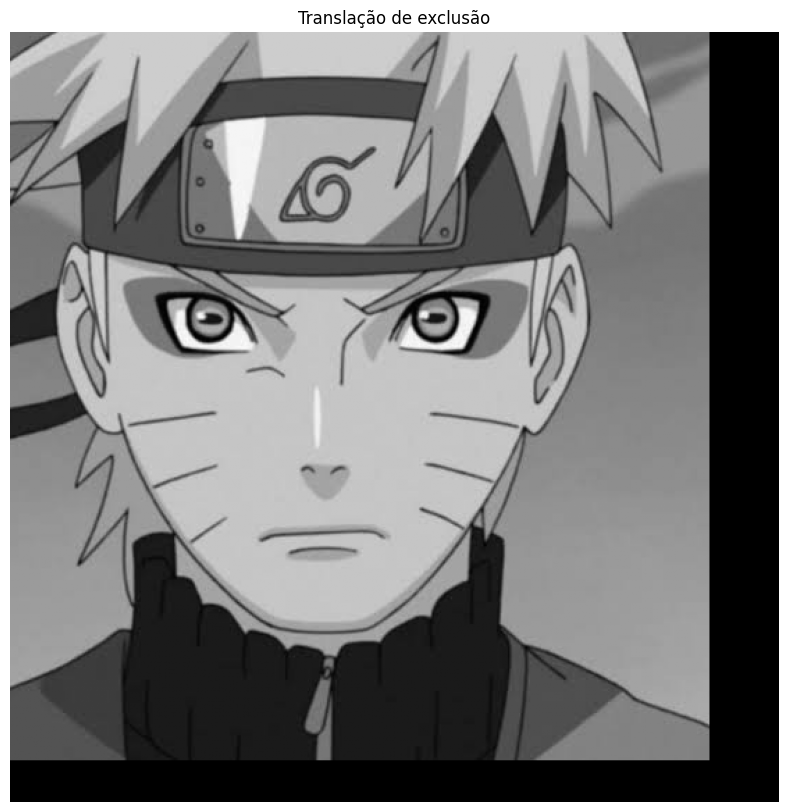

In [22]:
dx = 50
dy = 30

transladada = np.zeros((alt, lar), dtype=np.uint8)

for x in range(lar):
  for y in range(alt):

    novo_x = x + dx
    novo_y = y + dy

    if 0 <= novo_x and novo_x < lar:
      if 0 <= novo_y and novo_y < alt:
        transladada[y, x] = img_gray[novo_y, novo_x]

plt.figure(figsize=(10,10))
plt.imshow(transladada, cmap='gray')
plt.title('Translação de exclusão')
plt.axis('off')
plt.show()

# Translação de wrap-around

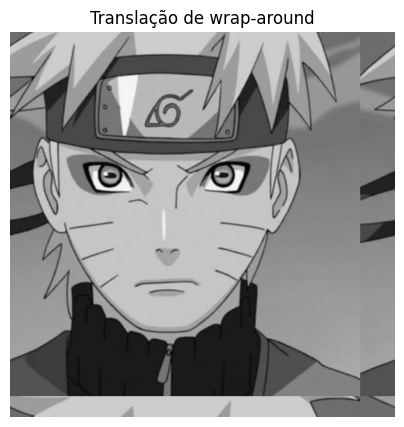

In [27]:
dx = 50
dy = 30

transladada = np.zeros((alt, lar), dtype=np.uint8)

for x in range(lar):
  for y in range(alt):

    novo_x = (x + dx) % lar
    novo_y = (y + dy) % alt

    if 0 <= novo_x and novo_x < lar:
      if 0 <= novo_y and novo_y < alt:
        transladada[y, x] = img_gray[novo_y, novo_x]

plt.figure(figsize=(7,5))
plt.imshow(transladada, cmap='gray')
plt.title('Translação de wrap-around')
plt.axis('off')
plt.show()

# Escalamento

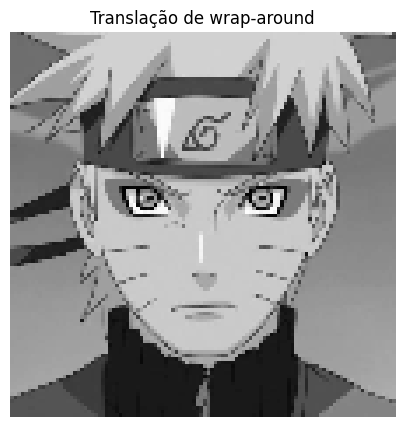

In [35]:
sx = 0.2
sy = 0.2

nova_largura = int(lar * sx)
nova_altura = int(alt * sy)
escalada = np.zeros((nova_altura, nova_largura), dtype=np.uint8)

for x in range(nova_largura):
  for y in range(nova_altura):

    novo_x = int(x / sx)
    novo_y = int(y / sy)

    escalada[y, x] = img_gray[novo_y, novo_x]

plt.figure(figsize=(7,5))
plt.imsave('naruto_escalado.jpg', escalada, cmap='gray')
plt.imshow(escalada, cmap='gray')
plt.title('Translação de wrap-around')
plt.axis('off')
plt.show()

# Espelhamento

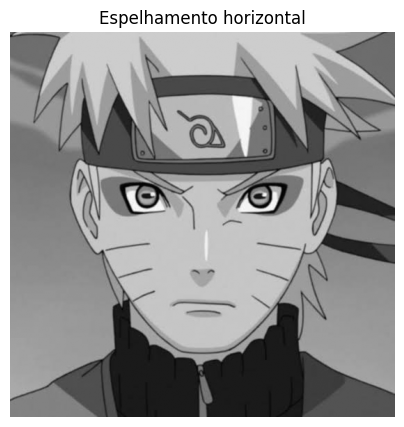

In [39]:
espelhada_h = np.zeros((alt, lar), dtype=np.uint8)

for x in range(lar):
  for y in range(alt):

    novo_x = lar - 1 - x

    espelhada_h[y, novo_x] = img_gray[y, x]

plt.figure(figsize=(7,5))
plt.imshow(espelhada_h, cmap='gray')
plt.title('Espelhamento horizontal')
plt.axis('off')
plt.show()